In [1]:
%load_ext autoreload
%autoreload 2

[PyTorch Tutorial](https://docs.pytorch.org/tutorials/intermediate/reinforcement_q_learning.html)

# Imports

In [2]:
from src.app import run
from src.game import Screen, Game
from src.config.enums import Direction
from src.ai.memory import ReplayMemory, Transition

C:\Users\alast\dev\uni-dev\mat502-ai\mat501-coursework-project\.venv\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [3]:
import math
import random
import matplotlib
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from itertools import count
from tqdm import tqdm

# Config

# Experiment

## Model

## Hyperparameters

## Config

### Game

## Training

In [6]:
screen = Screen(is_draw_enabled=False)
game = Game(
    screen,
    "MAT501 - Coursework",
    is_draw_enabled=False,
    framerate=0,
)
state = game.training_ai_get_current_snake_state()
data_cols = (
    list(range(len(state)-1)) + 
    [f"input_{direction.name}" for direction in list(Direction)] + 
    [f"current_{direction.name}" for direction in list(Direction)] + 
    ["reward"]
            )
data = pd.DataFrame(columns=data_cols)

num_episodes = 200
MAX_STEPS = 50
for i_episode in tqdm(range(num_episodes), ncols=100, position=0, leave=False):
    screen = Screen(is_draw_enabled=False)
    game = Game(
        screen,
        "MAT501 - Coursework",
        is_draw_enabled=False,
        framerate=0,
    )
    game_over = False
    for t in count():
        if t > MAX_STEPS:
            break
            
        game.training_ai_frame()
        for snake_idx in range(2):

            row = {k: 0 for k in data.columns}
            direction = list(Direction)[random.randint(0, len(list(Direction))-1)]
            state = game.training_ai_get_current_snake_state()
            observation, reward, game_over = game.training_ai_step(direction)
            
            for i in range(len(state)-1):
                row[i] = state[i]
            row[f"current_{state[4].name}"] = 1
            row[f"input_{direction.name}"] = 1
            row["reward"] = reward
    
            if len(data) > 0:
                data = pd.concat([data, pd.DataFrame([row])], ignore_index=True)
            else:
                data = pd.DataFrame([row])

            if game_over:
                break
                
        game.training_ai_end_frame()
        if game_over:
            break

R2:  0.9379844069480896


<Axes: >

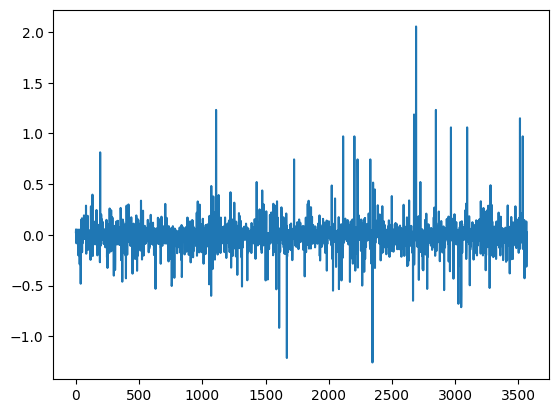

In [7]:
x_cols = [col for col in data.columns if col != "reward"]
y_col = ["reward"]
X_train, X_test, y_train, y_test = train_test_split(data[x_cols], data[y_col], test_size=0.33)
mdl = XGBRegressor(n_estimators=100)
mdl.fit(X_train, y_train)
predictions = mdl.predict(X_test)
print("R2: ", r2_score(y_test, predictions))
pd.Series(y_test.values.reshape(-1)-predictions).plot()

In [ ]:
RANDOM_MOVE_RATE = 0.1
num_episodes = 200
MAX_STEPS = 50
for i_episode in tqdm(range(num_episodes), ncols=100, position=0, leave=False):
    screen = Screen(is_draw_enabled=False)
    game = Game(
        screen,
        "MAT501 - Coursework",
        is_draw_enabled=False,
        framerate=0,
    )
    game_over = False
    
    for t in count():
        if t > MAX_STEPS:
            break
            
        game.training_ai_frame()
        for snake_idx in range(2):
    
            row = {k: 0 for k in data.columns}
            state = game.training_ai_get_current_snake_state()
            input_rows = []
            for direction in list(Direction):
                input_row = {k: 0 for k in data_cols}
                for i in range(len(state)-1):
                    input_row[i] = state[i]
                input_row[f"current_{state[4].name}"] = 1
                input_row[f"input_{direction.name}"] = 1
                input_rows.append(input_row)
            input_rows = pd.DataFrame(input_rows).drop("reward", axis=1)
    
            if random.random() > RANDOM_MOVE_RATE:
                direction = list(Direction)[mdl.predict(input_rows).argmax()]
            else:
                direction = list(Direction)[random.randint(0, len(list(Direction))-1)]
            
            observation, reward, game_over = game.training_ai_step(direction)
        
            for i in range(len(state)-1):
                row[i] = state[i]
            row[f"current_{state[4].name}"] = 1
            row[f"input_{direction.name}"] = 1
            row["reward"] = reward
            
            if len(data) > 0:
                data = pd.concat([data, pd.DataFrame([row])], ignore_index=True)
            else:
                data = pd.DataFrame([row])

            if game_over:
                break
            
        game.training_ai_end_frame()
        if game_over:
            break

  2%|█▎                                                             | 4/200 [00:02<01:52,  1.75it/s]

R2:  1.0


<Axes: >

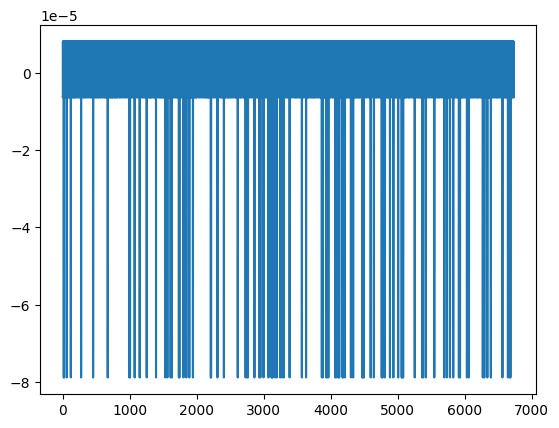

In [68]:
N_UPSAMPLES = 0

x_cols = [col for col in data.columns if col != "reward"]
y_col = ["reward"]
best_rewards_index = data[(data[y_col[0]] == 1.0)].index

upsampled_data = data.copy(deep=True)
for i in range(N_UPSAMPLES):
    upsampled_data = pd.concat([data, data.iloc[best_rewards_index]], ignore_index=True)

X_train, X_test, y_train, y_test = train_test_split(upsampled_data[x_cols], upsampled_data[y_col], test_size=0.33, shuffle=True)
mdl = XGBRegressor(n_estimators=100)
mdl.fit(X_train, y_train)
predictions = mdl.predict(X_test)
print("R2: ", r2_score(y_test, predictions))
pd.Series(y_test.values.reshape(-1)-predictions).plot()

# Test

In [69]:
is_draw_enabled = True
screen = Screen(is_draw_enabled=is_draw_enabled)
game = Game(
    screen,
    "MAT501 - Coursework",
    is_draw_enabled=is_draw_enabled,
    framerate=4,
)
game_over = False
for t in count():
    if t > 10_000:
        game.quit()
        break
    game.training_ai_frame()
    game.training_ai_step(Direction.UP)

    state = game.training_ai_get_current_snake_state()
    input_rows = []
    for direction in list(Direction):
        input_row = {k: 0 for k in data_cols}
        for i in range(len(state)-1):
            input_row[i] = state[i]
        input_row[f"current_{state[4].name}"] = 1
        input_row[f"input_{direction.name}"] = 1
        input_rows.append(input_row)
    input_rows = pd.DataFrame(input_rows).drop("reward", axis=1)
    direction = list(Direction)[mdl.predict(input_rows).argmax()]
    
    observation, reward, game_over = game.training_ai_step(direction)

    if game_over:
        break
    game.training_ai_end_frame()
